# 01. Навчання U-Net для реставрації баркодів

**Ідея:** CNN не читає баркод, а реставрує кадр: зіпсований -> чистий. Читає звичайний декодер.

```
зіпсований кадр -> U-Net -> декодер (zxing-cpp / OpenCV) -> рядок
```

**Пари для навчання** будуємо самі: `ціль = чистий кадр`, `вхід = той самий кадр +
випадкове пошкодження` (dark, uneven, glare, noise, motion_blur, defocus, jpeg; рівні 1-5).
Частина пар без пошкодження, щоб мережа вчилась не псувати хороші кадри.

**Три моделі, однакові налаштування, різні чисті кадри:**
- `synthetic`: згенеровані коди на білому фоні;
- `artelab`: реальні фото Arte-Lab (train-частина). Ділимо **за кодом**: той самий товар
  знято багато разів, і він має бути лише в train або лише в test;
- `mix`: синтетика + реальні фото приблизно навпіл.

**Швидкість:** мережа маленька (~1.9 млн параметрів), вчимо на шматках 128×128,
4000 кроків по 32 шматки. На Mac Mini M4 (MPS) ~10-12 хвилин на модель.

In [1]:
import sys
from pathlib import Path

# ноутбук лежить у notebooks/, корінь проєкту на рівень вище
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
MODELS = PROJECT_ROOT / "models"
RESULTS = PROJECT_ROOT / "results"
MODELS.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)

import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

In [2]:
from src.data import (generate_synthetic, label_by_consensus, load_artelab,
                      make_training_batch, split_by_code)
from src.model import UNet, get_device

# Синтетика: train і test з різним seed (різні коди)
synthetic_train = generate_synthetic(n_per_format=300, seed=1)
synthetic_test = generate_synthetic(n_per_format=30, seed=2)

# Arte-Lab: лише фото з відомою відповіддю, поділ за кодом
artelab = label_by_consensus(load_artelab())
artelab_train, artelab_test = split_by_code(artelab)

# Суміш: синтетичних кодів 900, реальних фото 167. Кадр для пари обирається випадково
# зі списку, тому реальні фото повторюємо 5 разів -> приблизно навпіл (900 і 835).
# Test для суміші = реальні фото, бо саме на них нам важливий результат.
mix_train = synthetic_train + artelab_train * 5

DATASETS = {
    "synthetic": (synthetic_train, synthetic_test),
    "artelab": (artelab_train, artelab_test),
    "mix": (mix_train, artelab_test),
}
for name, (train_part, test_part) in DATASETS.items():
    codes_train = set(s["text"] for s in train_part)
    codes_test = set(s["text"] for s in test_part)
    print(f"{name}: train {len(train_part)} кадрів ({len(codes_train)} кодів), "
          f"test {len(test_part)} кадрів ({len(codes_test)} кодів), "
          f"спільних кодів: {len(codes_train & codes_test)}")

synthetic: train 900 кадрів (900 кодів), test 90 кадрів (90 кодів), спільних кодів: 0
artelab: train 167 кадрів (28 кодів), test 87 кадрів (19 кодів), спільних кодів: 0
mix: train 1735 кадрів (928 кодів), test 87 кадрів (19 кодів), спільних кодів: 0


## Як виглядають пари (вгорі вхід, внизу ціль)

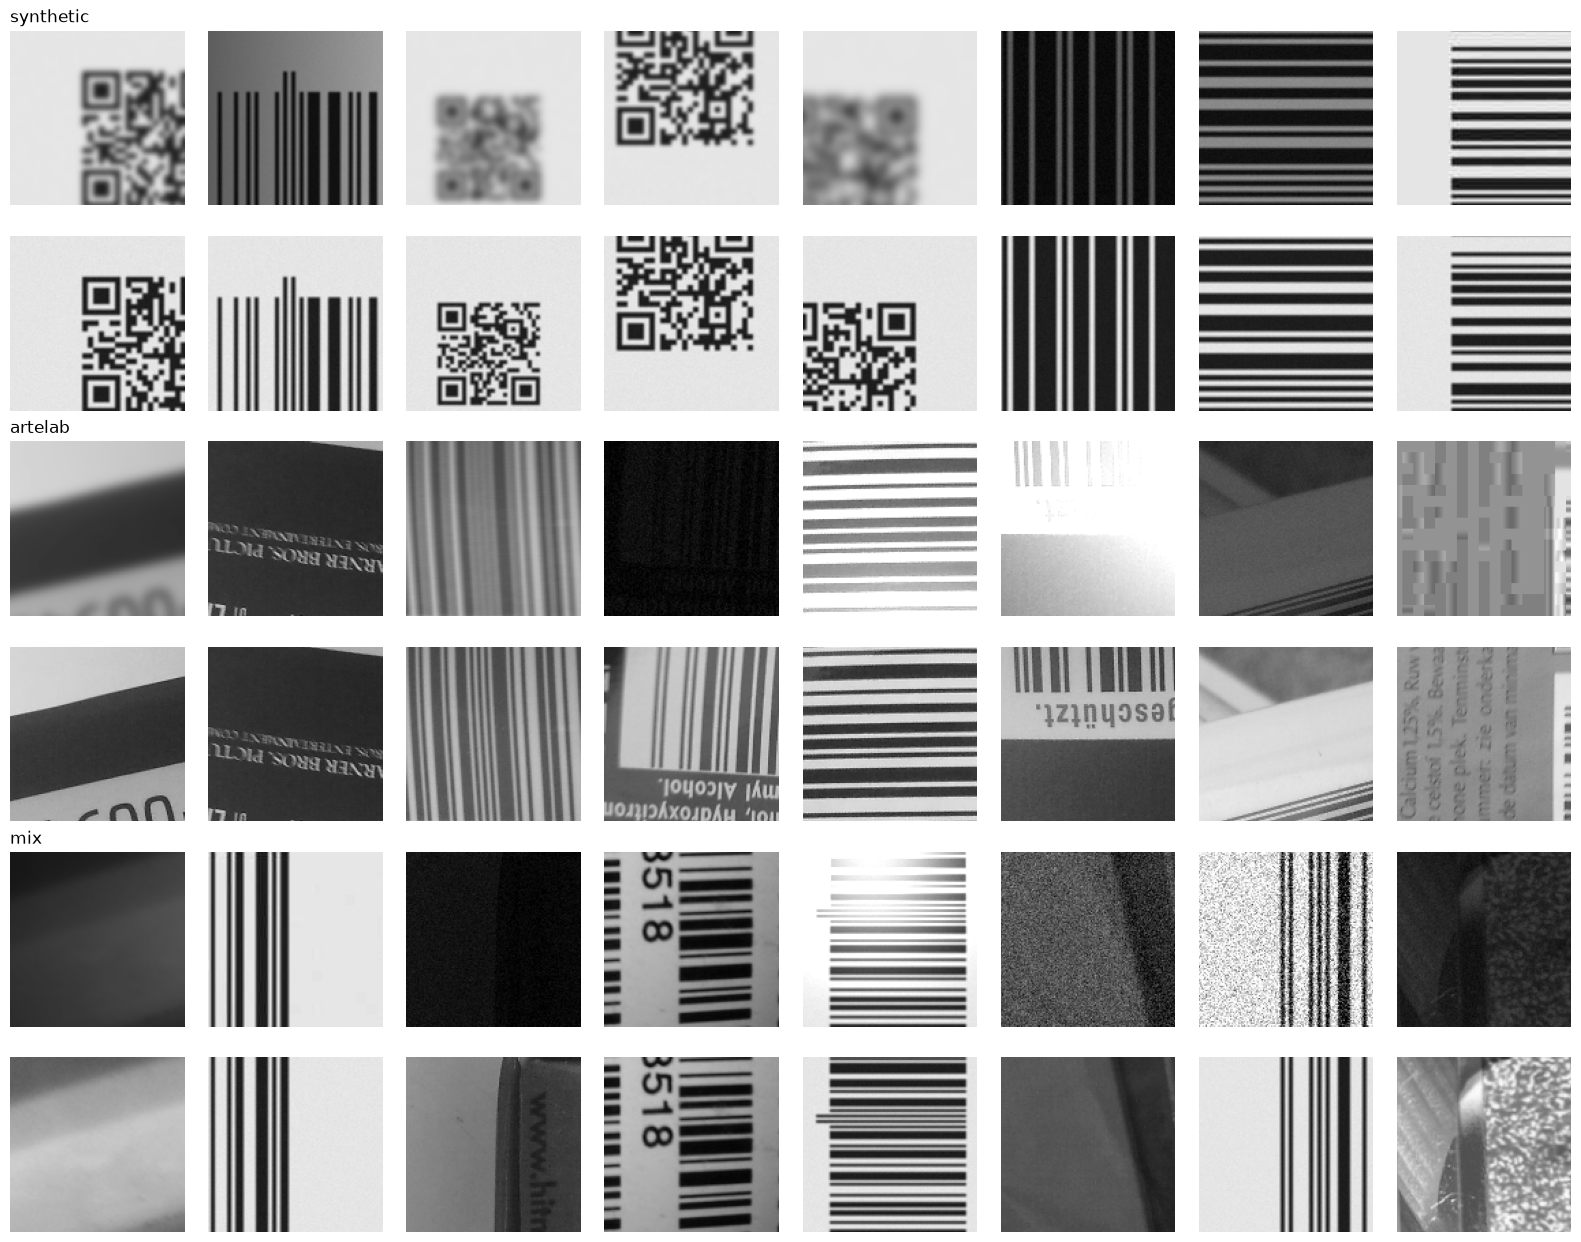

In [3]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(6, 8, figsize=(16, 12.5))
for row, name in enumerate(DATASETS):
    inputs, targets = make_training_batch(DATASETS[name][0], 8, rng)
    for i in range(8):
        axes[row * 2, i].imshow(inputs[i, 0], cmap="gray", vmin=0, vmax=1)
        axes[row * 2 + 1, i].imshow(targets[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[row * 2, 0].set_title(name, loc="left")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Навчання

- **Loss L1** = середня різниця яскравості між виходом мережі і чистим кадром.
- **Adam** змінює ваги так, щоб loss зменшувався.
- **Cosine schedule**: крок навчання (learning rate) плавно зменшується до кінця.
- **Test loss** рахуємо кожні 500 кроків на test-кадрах, яких мережа не бачить.
  Якщо train loss падає, а test loss росте, мережа запам'ятовує train (overfitting).

In [4]:
STEPS = 4000
BATCH = 32
device = get_device()
loss_fn = torch.nn.L1Loss()


@torch.no_grad()
def test_loss(model, test_part):
    """L1 на 8 фіксованих пачках з test (той самий rng щоразу -> чесне порівняння)."""
    model.eval()
    rng = np.random.default_rng(123)
    values = []
    for _ in range(8):
        inputs, targets = make_training_batch(test_part, BATCH, rng)
        outputs = model(torch.from_numpy(inputs).to(device))
        values.append(loss_fn(outputs, torch.from_numpy(targets).to(device)).item())
    model.train()
    return np.mean(values)


history = {}
for name, (train_part, test_part) in DATASETS.items():
    torch.manual_seed(0)
    model = UNet().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=STEPS)
    rng = np.random.default_rng(1)
    losses, test_losses = [], []
    start = time.time()
    model.train()
    for step in range(1, STEPS + 1):
        inputs, targets = make_training_batch(train_part, BATCH, rng)
        loss = loss_fn(model(torch.from_numpy(inputs).to(device)),
                       torch.from_numpy(targets).to(device))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()
        losses.append(loss.item())
        if step % 500 == 0:
            test_losses.append((step, test_loss(model, test_part)))
            print(f"{name} крок {step}: train {np.mean(losses[-500:]):.4f}, "
                  f"test {test_losses[-1][1]:.4f}, {time.time() - start:.0f} с")
    torch.save(model.state_dict(), MODELS / f"unet_{name}.pt")
    history[name] = (losses, test_losses)
    print("Збережено:", MODELS / f"unet_{name}.pt")

synthetic крок 500: train 0.0598, test 0.0327, 77 с


synthetic крок 1000: train 0.0339, test 0.0264, 154 с


synthetic крок 1500: train 0.0309, test 0.0238, 231 с


synthetic крок 2000: train 0.0272, test 0.0209, 308 с


synthetic крок 2500: train 0.0239, test 0.0200, 385 с


synthetic крок 3000: train 0.0218, test 0.0186, 463 с


... (14 outputs left out)

mix крок 2500: train 0.0621, test 0.0733, 412 с


mix крок 3000: train 0.0609, test 0.0718, 493 с


mix крок 3500: train 0.0583, test 0.0659, 575 с


mix крок 4000: train 0.0563, test 0.0667, 657 с
Збережено: /Users/andriizemlianyi/Code/zemand-learning/Computer Vision/r_d/r_d-computer-vision-project/models/unet_mix.pt


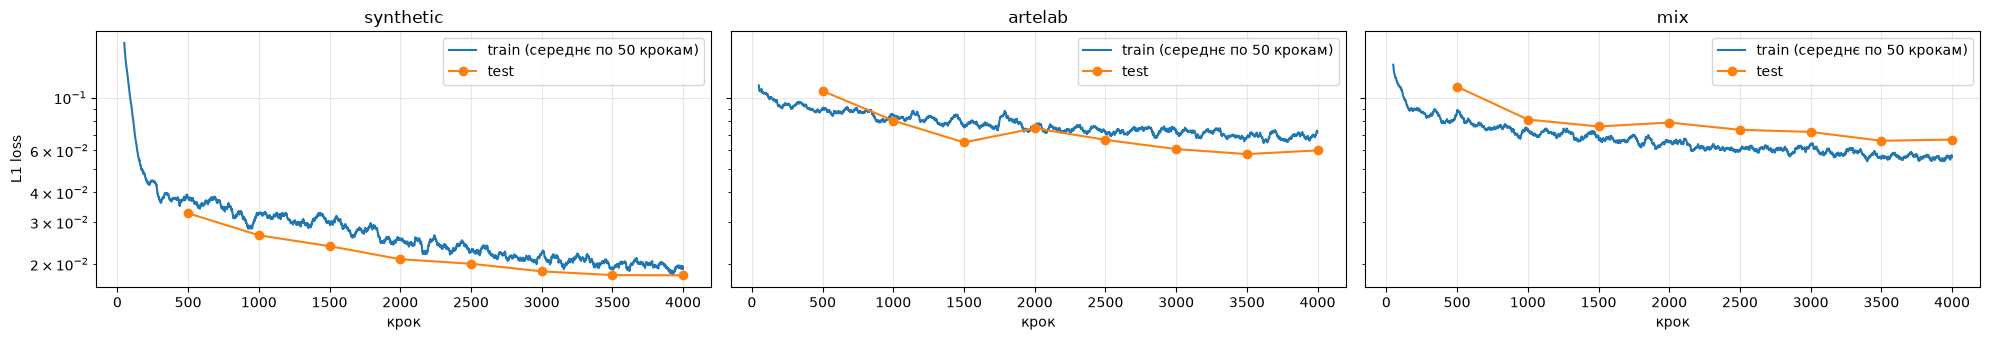

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(20, 3.5), sharey=True)
for ax, (name, (losses, test_losses)) in zip(axes, history.items()):
    ax.plot(pd.Series(losses).rolling(50).mean(), label="train (середнє по 50 крокам)")
    steps, values = zip(*test_losses)
    ax.plot(steps, values, "o-", label="test")
    ax.set_title(name)
    ax.set_xlabel("крок")
    ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("L1 loss")
plt.tight_layout()
plt.savefig(RESULTS / "fig_training.png", dpi=100)
plt.show()